# LTSM - Long Term Short Memory

In [1]:
! pip install tensorflow

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/351.2 MB 1.3 MB/s eta 0:04:27
   ---------------------------------------- 0.8/351.2 MB 1.4 MB/s eta 0:04:19
   ---------------------------------------- 1.0/351.2 MB 1.2 MB/s eta 0:04:44
   ---------------------------------------- 1.3/351.2 MB 1.3 MB/s eta 0:04:24
   ---------------------------------------- 1.6/351.2 MB 1.2 MB/s eta 0:04:46
   ---------------------------------------- 1.6/351.2 MB 1.2 MB/s eta 0:04:46
   ---------------------------------------- 2.1/351.2 MB 1.2 MB/s eta 0:04:48
   ---------------------------------------- 2.4/351.2 MB 1.2 MB/s eta 0:04:40
   ---------------------------------------- 2.6/351.2 MB 1.3 MB/s eta 0:04:35
   ---------------------------------------- 2.9/351.2 MB 1.3 MB/s eta 0:04:33
   ---------------------------------------- 3.1/351.2 MB 1.3 MB/s eta 0:04:26


In [14]:
# Imports
from tensorflow import keras
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler   
import matplotlib.pyplot as plt
import seaborn as sns
import os
from datetime import datetime

# Suppress TensorFlow warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'


In [15]:
data = pd.read_csv('MicrosoftStock.csv')
print(data.head())
print(data.info())
print(data.describe())

    index        date   open   high    low  close    volume  Name
0  390198  2013-02-08  27.35  27.71  27.31  27.55  33318306  MSFT
1  390199  2013-02-11  27.65  27.92  27.50  27.86  32247549  MSFT
2  390200  2013-02-12  27.88  28.00  27.75  27.88  35990829  MSFT
3  390201  2013-02-13  27.93  28.11  27.88  28.03  41715530  MSFT
4  390202  2013-02-14  27.92  28.06  27.87  28.04  32663174  MSFT
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   index   1259 non-null   int64  
 1   date    1259 non-null   object 
 2   open    1259 non-null   float64
 3   high    1259 non-null   float64
 4   low     1259 non-null   float64
 5   close   1259 non-null   float64
 6   volume  1259 non-null   int64  
 7   Name    1259 non-null   object 
dtypes: float64(4), int64(2), object(2)
memory usage: 78.8+ KB
None
               index         open         high          low 

Text(0.5, 1.0, 'Stock Volume over Time')

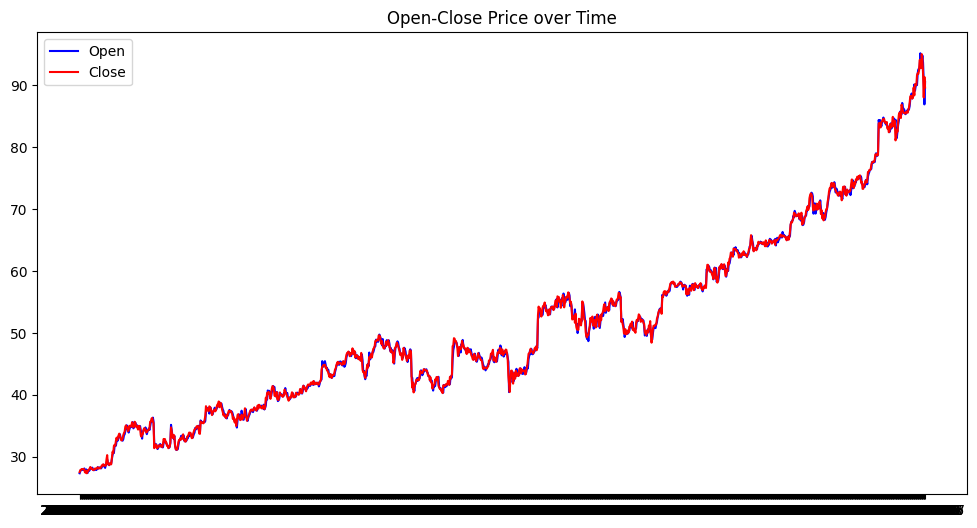

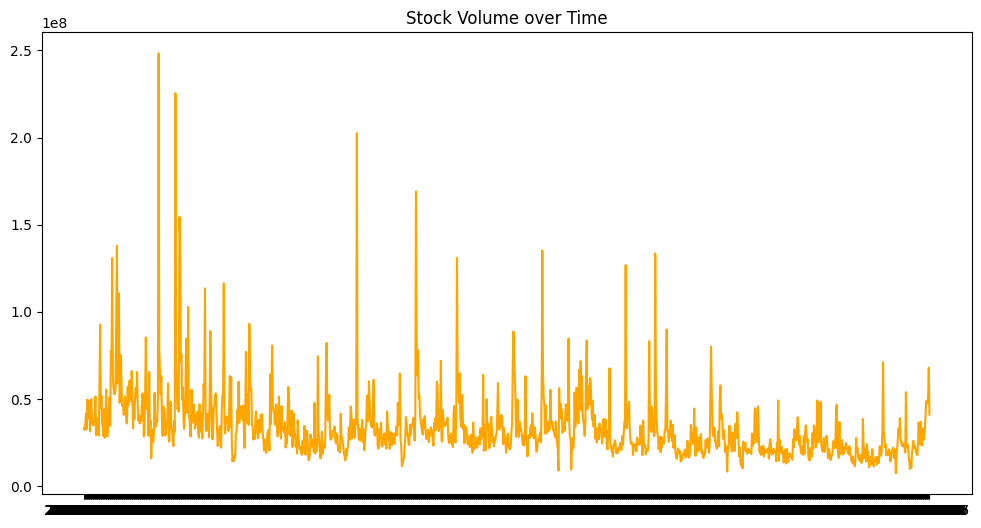

In [16]:
# Initial datat visulization

# Plot 1 - Open and Close Prices of time (to check the relation - correlation btw  Open and Close Prices)
plt.figure(figsize=(12,6))
plt.plot(data['date'], data['open'], label="Open",color="blue")
plt.plot(data['date'], data['close'], label="Close",color="red")
plt.title("Open-Close Price over Time")
plt.legend()
# plt.show()

# we can see that there is a huge relation btw the 2 features Open and Close Prices 

# Plot 2 - Trading Volume (check for outliers)
plt.figure(figsize=(12,6))
plt.plot(data['date'],data['volume'],label="Volume",color="orange")
plt.title("Stock Volume over Time")
# plt.show()

In [17]:
# Drop non numerical columns 
numeric_data = data.select_dtypes(include=["int64","float64"])
numeric_data

,index,open,high,low,close,volume
0,390198,27.35,27.710,27.3100,27.55,33318306
1,390199,27.65,27.920,27.5000,27.86,32247549
2,390200,27.88,28.000,27.7500,27.88,35990829
3,390201,27.93,28.110,27.8800,28.03,41715530
4,390202,27.92,28.060,27.8700,28.04,32663174
...,...,...,...,...,...,...
1254,391452,94.79,96.070,93.5813,94.26,47227882
1255,391453,93.64,93.970,91.5000,91.78,47867753
1256,391454,90.56,93.240,88.0000,88.00,51031465
1257,391455,86.89,91.475,85.2500,91.33,67998564


Text(0.5, 1.0, 'Feature Correlation Heatmap')

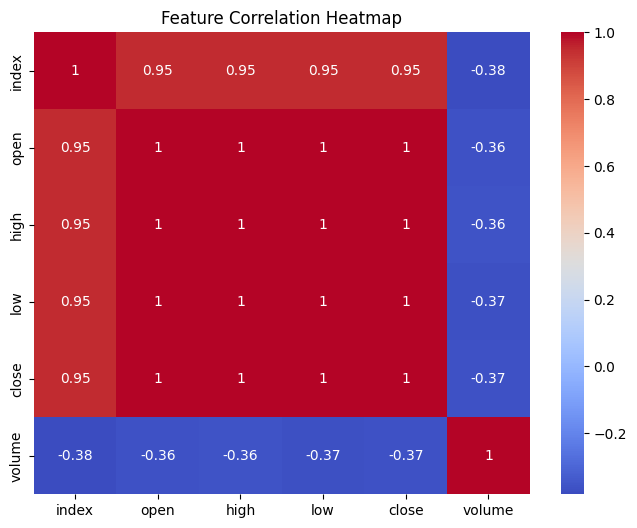

In [18]:
# Plot 3 - Check for correlation between features
plt.figure(figsize=(8,6))
sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
# plt.show()

Text(0.5, 1.0, 'Price over time')

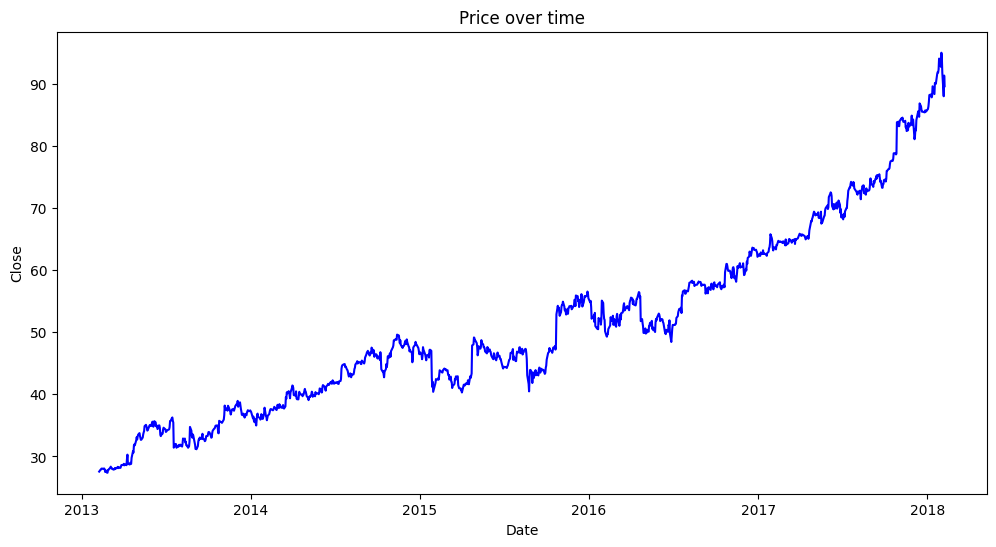

In [19]:
# Convert the Data into Date time then create a date filter 

data['date'] = pd.to_datetime(data['date']) # convert from object to datetime 

prediction = data.loc[                      #  create date filter 
    (data['date'] > datetime(2013,1,1)) &
    (data['date'] < datetime(2018,1,1))
]

# plot 
plt.figure(figsize=(12,6))
plt.plot(data['date'], data['close'],color="blue")
plt.xlabel("Date")
plt.ylabel("Close")
plt.title("Price over time")

In [20]:
# Prepare for the LSTM Model (Sequential)

stock_close  = data['close']
dataset = stock_close.values # convert to numy array 
training_data_len = int(np.ceil(len(dataset) * 0.95))


In [22]:
# Preprocesinng Stages
# Preprocessing Stages
scaler = StandardScaler()

# Reshape dataset into 2D (rows, 1 column)
scaled_data = scaler.fit_transform(dataset.reshape(-1, 1))

# Now you can split into training data
training_data = scaled_data[:training_data_len]  # 95% of all data
X_train, y_train = [], []



In [23]:
# Create a sliding window for our stock (60 days)
for i in range(60, len(training_data)):
    X_train.append(training_data[i-60:i, 0])
    y_train.append(training_data[i,0])
    
X_train, y_train = np.array(X_train), np.array(y_train)  # convert to numy array

X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))

In [25]:
# Build the Model 
model = keras.models.Sequential()

# First Layer
model.add(keras.layers.LSTM(64, return_sequences=True, input_shape=(X_train.shape[1],1)))

# 2nd Layer
model.add(keras.layers.LSTM(64, return_sequences=False ))

# 3nd Layer
model.add(keras.layers.Dense(128,activation='relu'))

# 4th Layer
model.add(keras.layers.Dropout(0.5))

# Final Output Layer
model.add(keras.layers.Dense(1))

model.summary()
model.compile(optimizer='adam', # optimiser
              loss='mae', # mesure error
              metrics=[keras.metrics.RootMeanSquaredError()]) # metrics 


C:\Users\hp\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 60, 64)              │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 58,369 (228.00 KB)

 Trainable params: 58,369 (228.00 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:

# training the model 
training = model.fit(X_train, y_train, epochs=20, batch_size=32)


Epoch 1/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 19s 86ms/step - loss: 0.2666 - root_mean_squared_error: 0.4033
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step - loss: 0.1289 - root_mean_squared_error: 0.1764
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - loss: 0.1191 - root_mean_squared_error: 0.1634
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 82ms/step - loss: 0.1138 - root_mean_squared_error: 0.1557
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - loss: 0.1121 - root_mean_squared_error: 0.1533
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - loss: 0.1125 - root_mean_squared_error: 0.1534
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - loss: 0.1090 - root_mean_squared_error: 0.1454
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - loss: 0.1056 - root_mean_squared_error: 0.1433
Epoch 9/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - loss: 0.1085 - root_mean_squared_error: 0.1466
Epoch 10/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - loss: 0.1076 - root_mean_squared_error: 0.147

In [27]:

# Prep the test data
test_data = scaled_data[training_data_len - 60:]
X_test, y_test = [], dataset[training_data_len:]


for i in range(60, len(test_data)):
    X_test.append(test_data[i-60:i, 0])
    
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0],X_test.shape[1],1 ))



In [28]:
# Make a Prediction
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 794ms/step


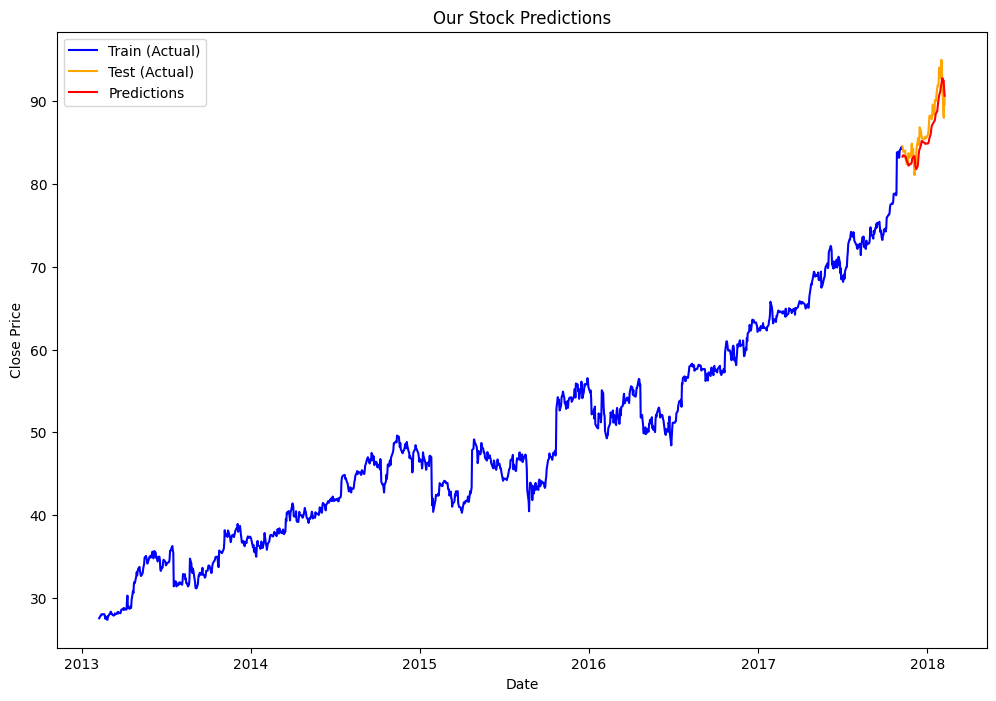

In [29]:
# Plotting data
train = data[:training_data_len]
test =  data[training_data_len:]

test = test.copy()

test['Predictions'] = predictions

plt.figure(figsize=(12,8))
plt.plot(train['date'], train['close'], label="Train (Actual)", color='blue')
plt.plot(test['date'], test['close'], label="Test (Actual)", color='orange')
plt.plot(test['date'], test['Predictions'], label="Predictions", color='red')
plt.title("Our Stock Predictions")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.show()